In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path

## Load database

In [2]:
# Setup pandas display options
pd.set_option('display.max_columns', None)

BASE_PATH = Path.cwd().parent
DATA_PATH = BASE_PATH / "researchment" / "database" / "indonesia_fintech_paylater.parquet"

# Load the dataset
df = pd.read_parquet(DATA_PATH)
df.head()

,borrower_id,age,gender,province,education_level,employment_status,monthly_income_idr,regional_minimum_wage_umr_idr,num_active_lending_apps,total_loan_outstanding_idr,credit_limit_granted_idr,loan_tenor_months,daily_interest_rate_pct,primary_loan_purpose,debt_to_income_ratio,income_to_umr_ratio,credit_limit_utilization_ratio,monthly_installment_estimate_idr,debt_service_ratio,disposable_income_after_debt_idr,days_past_due,financial_distress_index,twp90_default_status,primary_default_root_cause,cot_financial_psychology_rationale,confidence_score,risk_score,risk_short,is_high_risk,distress_bin
0,ID_DEB_00264B68D1,24,Female,Bali,High School / SMK,Micro-Entrepreneur / UMKM,6420000,2950000,2,8380000,12280000,1,0.35,Daily Living & Emergency Buffer,1.31,2.18,0.6824,9259900.0,1.4424,-2839900.0,67,3.97,Doubtful-DPD61-90,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_00264B68D1' (Female, usia 24 t...",0.961,3,Doubt(61-90),True,"(3.686, 4.588]"
1,ID_DEB_0DE3583B12,28,Female,Bali,Bachelor (S1),Formal Private Employee,8630000,2950000,1,20110000,29060000,6,0.30,Daily Living & Emergency Buffer,2.33,2.93,0.6920,5161567.0,0.5981,3468433.0,11,4.87,Special-Mention-DPD1-30,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_0DE3583B12' (Female, usia 28 t...",0.975,1,SM(1-30),False,"(4.588, 5.49]"
2,ID_DEB_0F661FADC0,20,Female,Bali,High School / SMK,Civil Servant / BUMN,5720000,2950000,4,14960000,23900000,1,0.32,Daily Living & Emergency Buffer,2.62,1.94,0.6259,16396160.0,2.8665,-10676160.0,180,6.07,Default-Macet-TWP90,High-Interest-Rate-Compounding,"Debitur 'ID_DEB_0F661FADC0' (Female, usia 20 t...",0.990,4,Default Rate(>90),True,"(5.49, 6.392]"
3,ID_DEB_10C74D3F21,31,Female,Bali,Bachelor (S1),Civil Servant / BUMN,11780000,2950000,3,7620000,26130000,1,0.26,Daily Living & Emergency Buffer,0.65,3.99,0.2916,8214360.0,0.6973,3565640.0,24,2.35,Special-Mention-DPD1-30,Compulsive-FOMO-Spending,"Debitur 'ID_DEB_10C74D3F21' (Female, usia 31 t...",0.977,1,SM(1-30),False,"(1.882, 2.784]"
4,ID_DEB_12CFCAE01F,22,Male,Bali,Bachelor (S1),Formal Private Employee,6490000,2950000,2,11080000,16420000,9,0.23,Daily Living & Emergency Buffer,1.71,2.20,0.6748,1995631.0,0.3075,4494369.0,0,4.43,Current-Performing,Compulsive-FOMO-Spending,"Debitur 'ID_DEB_12CFCAE01F' (Male, usia 22 tah...",0.980,0,Current,False,"(3.686, 4.588]"


### - **🎯 Task 2: Gen Z Debt-to-Income (DTI) & Financial Distress Index Forecasting**
###    - **Objective:** Forecast continuous `debt_to_income_ratio` and `financial_distress_index` from demographic, educational, and app multiplicity features to establish pre-emptive credit limits and debt caps.
###    - **Recommended ML Models:** Bayesian Ridge Regression, CatBoost Regressor, Deep learning tensorflow.keras (Priority).
###    - **Evaluation Metrics:** `Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), R-Squared (R²)`

## Feature Engineering

In [3]:
# Add datetime features on df
np.random.seed(42)

# Define a realistic time window (e.g. past 2 years up to today)
start_date = pd.to_datetime('2024-11-05')
end_date = pd.to_datetime('2026-11-05')

# Generate 10000 random timestamps between these dates
random_timestamps = np.random.randint(int(start_date.timestamp()), int(end_date.timestamp()), size=len(df))

# Add timestamp features to the DataFrame
df['date'] = pd.to_datetime(random_timestamps, unit='s')
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['is_weekend'] = (df['date'].dt.dayofweek >= 5).astype(int)
df['hour'] = df['date'].dt.strftime('%H:%M:%S')

# Move the date column to the first position
date_col = "date"
columns_move = df.columns.tolist()
columns_move.remove(date_col)

borrower_index = columns_move.index("borrower_id")
columns_move.insert(borrower_index + 1, date_col)

df = df[columns_move]

# Sort the DataFrame by the new 'date' column
df = df.sort_values(by='date').reset_index(drop=True)

In [4]:
# ---- Allowed pre-loan columns -----
ALLOWED_RAW = [
    "age", "gender", "province", "education_level", "employment_status",
    "monthly_income_idr", "regional_minimum_wage_umr_idr",
    "num_active_lending_apps", "credit_limit_granted_idr",
    "loan_tenor_months", "primary_loan_purpose", "daily_interest_rate_pct",
    "income_to_umr_ratio", "date"
]
TARGETS = ["debt_to_income_ratio", "financial_distress_index"]

# Define features
feats = df[ALLOWED_RAW].copy()

# ----- Engineered features -----
feats['year'] = feats['date'].dt.year
feats['month'] = feats['date'].dt.month
feats['day'] = feats['date'].dt.day
feats['is_weekend'] = (feats['date'].dt.dayofweek >= 5).astype(int)
feats['hour'] = feats['date'].dt.hour
feats['credit_limit_to_income'] = feats['credit_limit_granted_idr'] / (feats['monthly_income_idr'] + 1)
feats['credit_limit_to_umr']    = feats['credit_limit_granted_idr'] / (feats['regional_minimum_wage_umr_idr'] + 1)
feats['apps_per_income_m'] = feats['num_active_lending_apps'] / (feats['monthly_income_idr'] / 1e6 + 1)
feats['multi_app_flag'] = (feats['num_active_lending_apps'] >= 3).astype(int)
feats["total_interest_rate"] = feats["daily_interest_rate_pct"] * feats["loan_tenor_months"] * 30
feats["high_edu"] = feats["education_level"].isin(["Bachelor (S1)", "Master (S2)"]).astype(int)
feats["stable_emp"] = feats["employment_status"].isin(["Formal Private Employee","Civil Servant / BUMN"]).astype(int)
feats["income_stability"] = feats["high_edu"] * feats["stable_emp"]

In [5]:
# Grouping province stats
prov_stats = df.groupby('province').agg(
    prov_avg_income=('monthly_income_idr', 'mean'),
    prov_avg_umr=('regional_minimum_wage_umr_idr', 'mean')
).reset_index()

# Merge province stats back to features
feats = feats.merge(prov_stats, on='province', how='left')
feats['income_vs_prov_avg'] = feats['monthly_income_idr'] / (feats['prov_avg_income'] + 1)

In [6]:
# Purpose tier for grouping
PURPOSE_TIER = {"Consumptive":1,"Shopping":1,"Entertainment":1,
                "Education":2,"Medical":2,
                "Business":3,"Working Capital":3,"Productive":3}
feats['purpose_tier'] = feats['primary_loan_purpose'].map(PURPOSE_TIER).fillna(2)

# Build the targets DataFrame
y_dti = df['debt_to_income_ratio'].values.astype("float32")
y_distress = df['financial_distress_index'].values.astype("float32")

## Preprocessing task

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

cat_cols = feats.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = feats.select_dtypes(include=['number']).columns.tolist()

# 1. First split: Separate out a hold-out test set (e.g., 20%)
idx = np.arange(len(feats))
idx_tr_full, idx_te = train_test_split(idx, test_size=0.2, random_state=42)

# 2. Second split: Split the remaining training data into Train and Validation (e.g., 85% train, 15% val)
idx_tr, idx_val = train_test_split(idx_tr_full, test_size=0.15, random_state=42)

# Slice raw features
X_tr_raw, X_val_raw, X_te_raw = feats.iloc[idx_tr], feats.iloc[idx_val], feats.iloc[idx_te]

# slice targets
y_dti_tr, y_dti_val, y_dti_te = y_dti[idx_tr], y_dti[idx_val], y_dti[idx_te]
y_dis_tr, y_dis_val, y_dis_te = y_distress[idx_tr], y_distress[idx_val], y_distress[idx_te]

# 3. Fit ColumnTransformer EXCLUSIVELY on X_tr_raw
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

# Scale training, test, & validation features
X_tr = preprocess.fit_transform(X_tr_raw).astype("float32")
X_val = preprocess.transform(X_val_raw).astype("float32")
X_te = preprocess.transform(X_te_raw).astype("float32")

# Scale fit & transform on the targets
scaler_dti_y = StandardScaler()
scaler_dis_y = StandardScaler()

# Scale only training & validation targets
y_dti_tr_s = scaler_dti_y.fit_transform(y_dti_tr.reshape(-1, 1)).astype("float32")
y_dis_tr_s = scaler_dis_y.fit_transform(y_dis_tr.reshape(-1, 1)).astype("float32")
y_dti_val_s = scaler_dti_y.transform(y_dti_val.reshape(-1, 1)).astype("float32")
y_dis_val_s = scaler_dis_y.transform(y_dis_val.reshape(-1, 1)).astype("float32")

print(f"Training set shape: {X_tr.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Testing set shape: {X_te.shape}")

Training set shape: (6800, 55)
Validation set shape: (1200, 55)
Testing set shape: (2000, 55)


In [8]:
assert len(feats) == len(df)
assert feats.index.equals(df.index), "Feature and target indices are misaligned!"

print("Feature-target alignment: OK")

Feature-target alignment: OK


## Build the Multi-Output Neural Network

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

def build_multi_output_model(input_dim, lr=3e-4):
    """
    Build a multi-output neural network model.
    
    Returns:
        model: A compiled Keras model with two layers outputs.
    """
    inputs = layers.Input(shape=(input_dim, ), name="features")

    # Shared trunk
    x = layers.Dense(128, kernel_initializer='he_normal')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.1)(x)

    x = layers.Dense(64, kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.1)(x)

    # Shared representation
    shared = layers.Dense(32, activation='relu')(x)

    # Head 1: DTI (Debt-to-Income Ratio)
    dti = layers.Dense(64, activation='relu')(shared)
    dti = layers.Dropout(0.1)(dti)
    dti = layers.Dense(32, activation='relu')(dti)
    out_dti = layers.Dense(1, name='dti')(dti)

    # Head 2: Financial Distress Index
    dis = layers.Dense(64, activation='relu')(shared)
    dis = layers.Dropout(0.1)(dis)
    dis = layers.Dense(32, activation='relu')(dis)
    out_dis = layers.Dense(1, name='distress')(dis)

    # Adam Optimizer with Gradient Clipping added
    optimizer = tf.keras.optimizers.Adam(
        learning_rate=lr,
        clipnorm=1.0  # Clip gradients by norm to prevent exploding gradients
    )

    # Map the output names to the corresponding heads
    model = keras.Model(
        inputs=inputs,
        outputs={
            "dti": out_dti,
            "distress": out_dis
        }
    )

    # Compile the model with appropriate loss functions and metrics for each output
    model.compile(
        optimizer=optimizer,
        loss={
            "dti": "mse",
            "distress": "mse"
        },
        loss_weights={
            "dti": 1.0, 
            "distress": 1.0
        },
        metrics={
            "dti": [tf.keras.metrics.R2Score(name="r2")],
            "distress": [tf.keras.metrics.R2Score(name="r2")]
        }
    )
    
    return model

model = build_multi_output_model(X_tr.shape[1])
model.summary()

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

2026-11-06 20:38:28.508933: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-11-06 20:38:28.508958: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-11-06 20:38:28.508962: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-11-06 20:38:28.508982: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-06 20:38:28.508992: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 features (InputLayer)       [(None, 55)]                 0         []                            
                                                                                                  
 dense (Dense)               (None, 128)                  7168      ['features[0][0]']            
                                                                                                  
 batch_normalization (Batch  (None, 128)                  512       ['dense[0][0]']               
 Normalization)                                                                                   
                                                                                                  
 activation (Activation)     (None, 128)                  0         ['batch_normalization[0][0

## Training with callbacks + tqdm

In [ ]:
callbacks_list = [
    callbacks.EarlyStopping(
        monitor='val_loss', 
        patience=15, 
        restore_best_weights=True, 
        mode='min'
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss', 
        factor=0.5, 
        patience=5, 
        min_lr=1e-6, 
        verbose=1
    )
]

# Train the model
history = model.fit(
    X_tr,
    {
        "dti": y_dti_tr_s, 
        "distress": y_dis_tr_s
    },    
    validation_data=(X_val, 
                     {
                         "dti": y_dti_val_s, 
                         "distress": y_dis_val_s
                     }),
    epochs=150,
    batch_size=128,
    callbacks=callbacks_list,
    verbose=1
)


Epoch 1/150


2026-11-06 20:38:29.153007: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


54/54 [==============================] - 2s 24ms/step - loss: 1.7494 - dis_loss: 0.8205 - dti_loss: 0.9289 - dis_r2: 0.1795 - dti_r2: 0.0711 - val_loss: 0.9161 - val_dis_loss: 0.3890 - val_dti_loss: 0.5271 - val_dis_r2: 0.6175 - val_dti_r2: 0.4908 - lr: 0.0010
Epoch 2/150
54/54 [==============================] - 1s 15ms/step - loss: 0.9919 - dis_loss: 0.4555 - dti_loss: 0.5363 - dis_r2: 0.5445 - dti_r2: 0.4637 - val_loss: 0.7136 - val_dis_loss: 0.2960 - val_dti_loss: 0.4177 - val_dis_r2: 0.7089 - val_dti_r2: 0.5966 - lr: 0.0010
Epoch 3/150
54/54 [==============================] - 1s 15ms/step - loss: 0.8434 - dis_loss: 0.3832 - dti_loss: 0.4602 - dis_r2: 0.6168 - dti_r2: 0.5398 - val_loss: 0.6866 - val_dis_loss: 0.2948 - val_dti_loss: 0.3918 - val_dis_r2: 0.7101 - val_dti_r2: 0.6215 - lr: 0.0010
Epoch 4/150
54/54 [==============================] - 1s 14ms/step - loss: 0.8258 - dis_loss: 0.3916 - dti_loss: 0.4342 - dis_r2: 0.6084 - dti_r2: 0.5658 - val_loss: 0.6246 - val_dis_loss: 0.297

In [11]:
history_df = pd.DataFrame(history.history)
history_df

,loss,dis_loss,dti_loss,dis_r2,dti_r2,val_loss,val_dis_loss,val_dti_loss,val_dis_r2,val_dti_r2,lr
0,1.749351,0.820479,0.928872,0.179521,0.071128,0.916126,0.388983,0.527143,0.617452,0.490844,0.001000
1,0.991864,0.455539,0.536325,0.544461,0.463675,0.713631,0.295968,0.417663,0.708928,0.596588,0.001000
2,0.843423,0.383233,0.460190,0.616767,0.539810,0.686620,0.294798,0.391822,0.710079,0.621547,0.001000
3,0.825798,0.391614,0.434184,0.608386,0.565816,0.624598,0.297665,0.326934,0.707259,0.684222,0.001000
4,0.824603,0.371420,0.453184,0.628580,0.546816,0.760913,0.350247,0.410666,0.655546,0.603346,0.001000
...,...,...,...,...,...,...,...,...,...,...,...
58,0.810887,0.430017,0.380870,0.569983,0.619130,0.489752,0.244992,0.244761,0.759061,0.763591,0.000004
59,0.811601,0.429388,0.382213,0.570612,0.617787,0.490898,0.244402,0.246495,0.759641,0.761915,0.000004
60,0.801054,0.423865,0.377189,0.576135,0.622811,0.487692,0.243130,0.244562,0.760892,0.763783,0.000004
61,0.822318,0.432142,0.390176,0.567858,0.609824,0.488761,0.243819,0.244941,0.760214,0.763416,0.000004


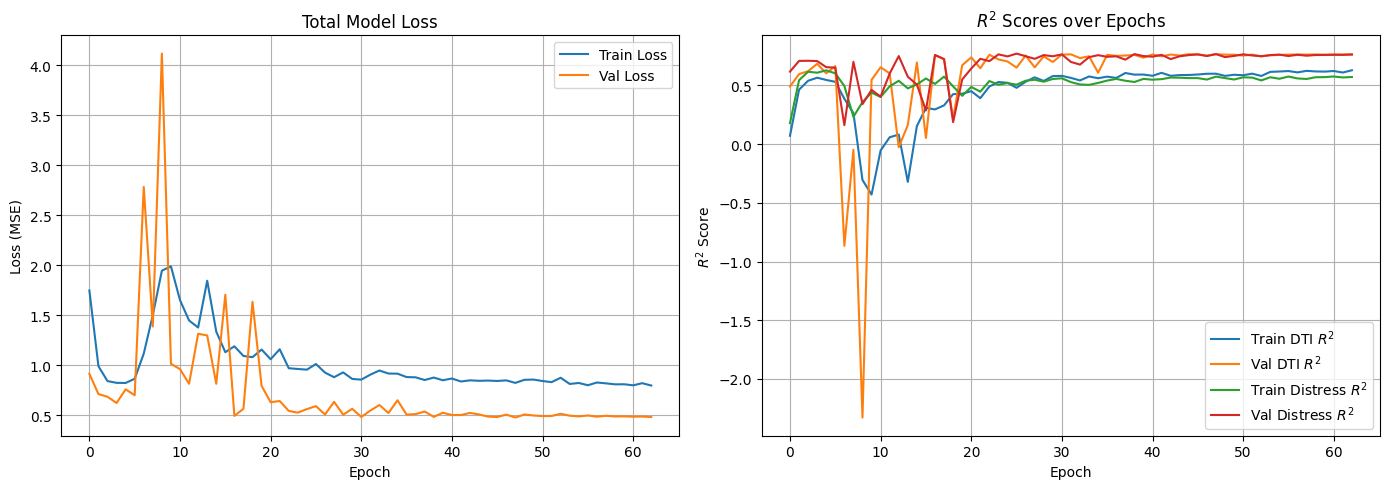

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Total Model Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (MSE)')
axes[0].legend()
axes[0].grid(True)

# R2 Score plot for DTI and Distress
axes[1].plot(history.history['dti_r2'], label='Train DTI $R^2$')
axes[1].plot(history.history['val_dti_r2'], label='Val DTI $R^2$')
axes[1].plot(history.history['dis_r2'], label='Train Distress $R^2$')
axes[1].plot(history.history['val_dis_r2'], label='Val Distress $R^2$')
axes[1].set_title('$R^2$ Scores over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('$R^2$ Score')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Try different evaluation

In [13]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pred = model.predict(X_te)

pred_dti = scaler_dti_y.inverse_transform(np.asarray(pred["dti"]).reshape(-1, 1)).ravel()
pred_dis = scaler_dis_y.inverse_transform(np.asarray(pred["distress"]).reshape(-1, 1)).ravel()

actual_dti = np.asarray(y_dti_te).ravel()
actual_dis = np.asarray(y_dis_te).ravel()

for name, actual, predicted in [
    ("DTI", actual_dti, pred_dti),
    ("Distress", actual_dis, pred_dis)
]:
    print(f"\n{name}")
    print(f"R2:   {r2_score(actual, predicted):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(actual, predicted)):.4f}")
    print(f"MAE:  {mean_absolute_error(actual, predicted):.4f}")

63/63 [==============================] - 0s 2ms/step

DTI
R2:   0.7536
RMSE: 0.4322
MAE:  0.3530

Distress
R2:   0.7515
RMSE: 1.0482
MAE:  0.8669
